In [13]:
# %% [Cell 1] Импорты и настройки
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import (
    classification_report, precision_recall_curve, auc,
    f1_score, average_precision_score, roc_auc_score,
    precision_score, recall_score,
)

plt.style.use('seaborn-v0_8-whitegrid')
np.random.seed(42)

In [14]:
PATH = "creditcard.csv"

df = pd.read_csv(PATH)
print(f"форма датасета: {df.shape}")
print(f"колонки: {list(df.columns)[:5]} ... {list(df.columns)[-3:]}")

print("\nбаланс классов:")
print(df['Class'].value_counts())
fraud_rate = df['Class'].mean() * 100
print(f"доля мошенничества: {fraud_rate:.4f}%  ← экстремальный дисбаланс")

print(f"\nпропусков: {df.isna().sum().sum()}")

форма датасета: (284807, 31)
колонки: ['Time', 'V1', 'V2', 'V3', 'V4'] ... ['V28', 'Amount', 'Class']

баланс классов:
Class
0    284315
1       492
Name: count, dtype: int64
доля мошенничества: 0.1727%  ← экстремальный дисбаланс

пропусков: 0


In [15]:
scaler_amount = StandardScaler()
scaler_time   = StandardScaler()

df['scaled_amount'] = scaler_amount.fit_transform(df['Amount'].values.reshape(-1, 1))
df['scaled_time']   = scaler_time.fit_transform(df['Time'].values.reshape(-1, 1))

features = ['scaled_time'] + [f'V{i}' for i in range(1, 29)] + ['scaled_amount']
X = df[features].values
y = df['Class'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"train: {X_train.shape},  фрод в train: {y_train.sum()} ({y_train.mean()*100:.4f}%)")
print(f"test:  {X_test.shape},  фрод в test:  {y_test.sum()} ({y_test.mean()*100:.4f}%)")

X_train_normal = X_train[y_train == 0]
print(f"нормальных в train (для fit детекторов): {X_train_normal.shape[0]}")

train: (227845, 30),  фрод в train: 394 (0.1729%)
test:  (56962, 30),  фрод в test:  98 (0.1720%)
нормальных в train (для fit детекторов): 227451


In [ ]:
t0 = time.time()
iso = IsolationForest(
    n_estimators=200,
    contamination=0.001,
    random_state=42,
    n_jobs=-1,
)
iso.fit(X_train_normal)
print(f"Isolation Forest обучен за {time.time() - t0:.2f} c")


scores_iso = -iso.score_samples(X_test)

Isolation Forest обучен за 5.97 c


In [17]:
t0 = time.time()
lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.001,
    novelty=True,
    n_jobs=-1,
)
lof.fit(X_train_normal)
print(f"LOF обучен за {time.time() - t0:.2f} c")

scores_lof = -lof.decision_function(X_test)

LOF обучен за 86.24 c


In [18]:
def evaluate(name, scores, y_true, n_points=100):
    prec, rec, thr = precision_recall_curve(y_true, scores)
    pr_auc = auc(rec, prec)
    ap     = average_precision_score(y_true, scores)
    roc    = roc_auc_score(y_true, scores)

    thresholds = np.percentile(scores, np.linspace(80, 99.99, n_points))
    f1s = [f1_score(y_true, (scores > t).astype(int), zero_division=0) for t in thresholds]
    best_t   = thresholds[int(np.argmax(f1s))]
    y_pred   = (scores > best_t).astype(int)

    print(f"\n{name}")
    print(f"PR-AUC (area):         {pr_auc:.4f}")
    print(f"Average Precision:     {ap:.4f}")
    print(f"ROC-AUC (для сравнения):{roc:.4f}")
    print(f"Best F1:               {max(f1s):.4f}   (порог = {best_t:.4f})")
    print(classification_report(y_true, y_pred, target_names=['норма', 'фрод'], digits=4))
    return prec, rec, pr_auc

prec_iso, rec_iso, pr_auc_iso = evaluate("Isolation Forest", scores_iso, y_test)
prec_lof, rec_lof, pr_auc_lof = evaluate("LOF",              scores_lof, y_test)


Isolation Forest
PR-AUC (area):         0.1241
Average Precision:     0.1283
ROC-AUC (для сравнения):0.9531
Best F1:               0.2283   (порог = 0.6458)
              precision    recall  f1-score   support

       норма     0.9987    0.9983    0.9985     56864
        фрод     0.2066    0.2551    0.2283        98

    accuracy                         0.9970     56962
   macro avg     0.6027    0.6267    0.6134     56962
weighted avg     0.9974    0.9970    0.9972     56962


LOF
PR-AUC (area):         0.0065
Average Precision:     0.0068
ROC-AUC (для сравнения):0.7120
Best F1:               0.0412   (порог = -3.7440)
              precision    recall  f1-score   support

       норма     0.9985    0.9900    0.9943     56864
        фрод     0.0241    0.1429    0.0412        98

    accuracy                         0.9886     56962
   macro avg     0.5113    0.5664    0.5177     56962
weighted avg     0.9968    0.9886    0.9926     56962



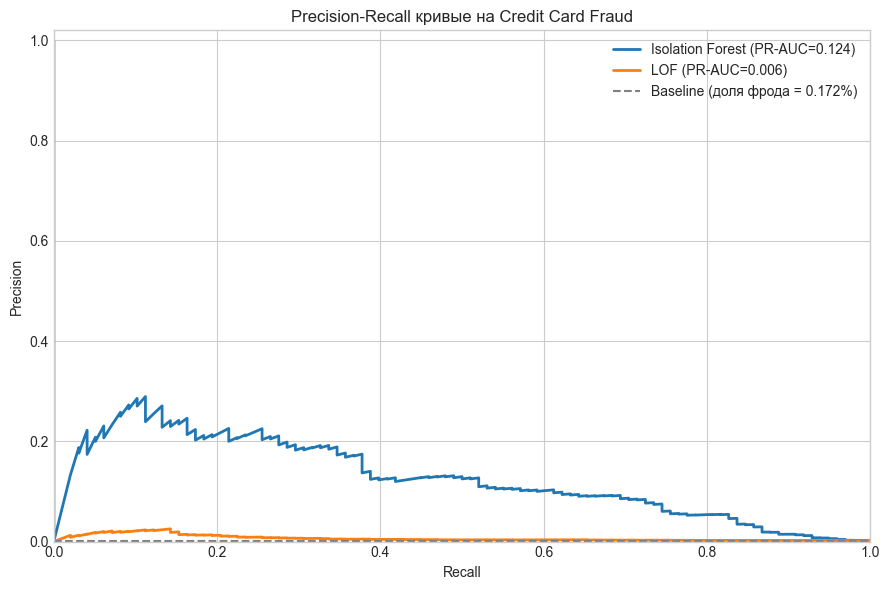

In [19]:
plt.figure(figsize=(9, 6))
plt.plot(rec_iso, prec_iso, linewidth=2, label=f'Isolation Forest (PR-AUC={pr_auc_iso:.3f})')
plt.plot(rec_lof, prec_lof, linewidth=2, label=f'LOF (PR-AUC={pr_auc_lof:.3f})')
plt.axhline(y_test.mean(), color='gray', linestyle='--',
            label=f'Baseline (доля фрода = {y_test.mean()*100:.3f}%)')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall кривые на Credit Card Fraud')
plt.legend()
plt.grid(True)
plt.xlim(0, 1); plt.ylim(0, 1.02)
plt.tight_layout()
plt.show()

In [20]:
rows = []
for cont in [0.0005, 0.001, 0.005, 0.01, 0.02]:
    m = IsolationForest(n_estimators=200, contamination=cont,
                        random_state=42, n_jobs=-1).fit(X_train_normal)
    y_pred = (m.predict(X_test) == -1).astype(int)
    rows.append({
        'contamination': cont,
        'flagged': y_pred.sum(),
        'precision': precision_score(y_test, y_pred, zero_division=0),
        'recall':    recall_score(y_test, y_pred),
        'f1':        f1_score(y_test, y_pred, zero_division=0),
    })

res = pd.DataFrame(rows)
print("Isolation Forest: влияние contamination на порог predict()")
print(res.to_string(index=False))

Isolation Forest: влияние contamination на порог predict()
 contamination  flagged  precision   recall       f1
        0.0005       39   0.282051 0.112245 0.160584
        0.0010       79   0.215190 0.173469 0.192090
        0.0050      331   0.123867 0.418367 0.191142
        0.0100      678   0.092920 0.642857 0.162371
        0.0200     1282   0.057722 0.755102 0.107246
